# Base 5: exploração, ACF, STL e tratamento

Este notebook transforma apenas a entrada estrutural da Base 5 em um CSV `cleaned`, sem alterar os arquivos congelados. A ACF e a STL usam o maior segmento regular e completo do alvo. Como nenhum segmento da Base 5 suporta dois ciclos anuais, os gráficos usam uma cópia exclusivamente diagnóstica com interpolação temporal das lacunas internas; o CSV `cleaned` permanece sem interpolação.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "configs").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from discovery_series_temporais.cleaning import build_cleaned_dataset, plot_cleaned_diagnostics

BASE_ID = 5
cleaned, summary = build_cleaned_dataset(BASE_ID, ROOT / "data" / "processed")
display(pd.DataFrame([{
    "base": summary.base_id,
    "target_original": summary.target_name,
    "rows": summary.rows,
    "columns": summary.columns,
    "missing_target": summary.missing_target,
    "cleaned_output": str(summary.output_path),
    "actions": "; ".join(summary.actions),
}]))
display(cleaned.head())
display(cleaned.isna().sum().rename("missing_values").to_frame())


,base,target_original,rows,columns,missing_target,cleaned_output,actions
0,5,GOLD_PRICE,2398,4,254,C:\Users\mayumishimizu-ieg\.codex\.chatgpt-pro...,resampled to Friday-ended weeks using the fina...


,timestamp,target,TREASURY_10Y,FED_FUNDS_RATE
0,1968-05-03,39.60,5.76,6.25
1,1968-05-10,39.70,5.80,5.50
2,1968-05-17,41.60,5.90,6.38
3,1968-05-24,41.75,5.98,6.25
4,1968-05-31,41.75,5.95,5.75


,missing_values
timestamp,0
target,254
TREASURY_10Y,254
FED_FUNDS_RATE,254


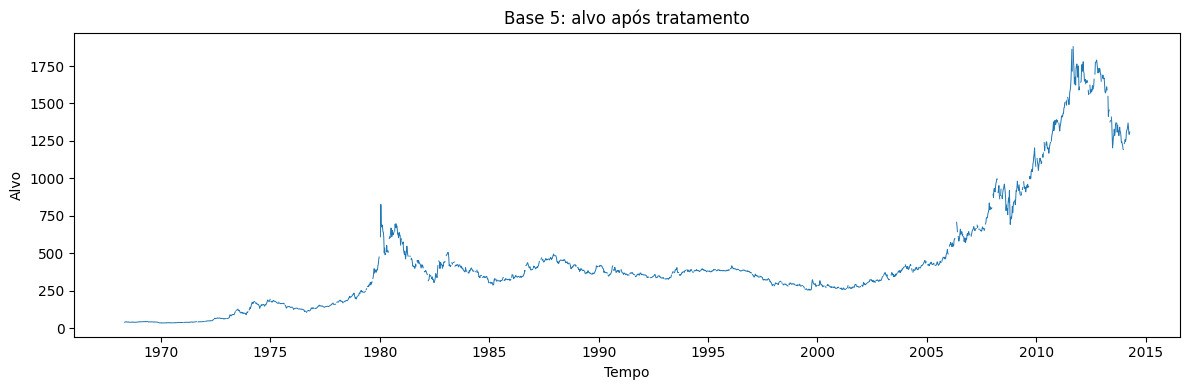

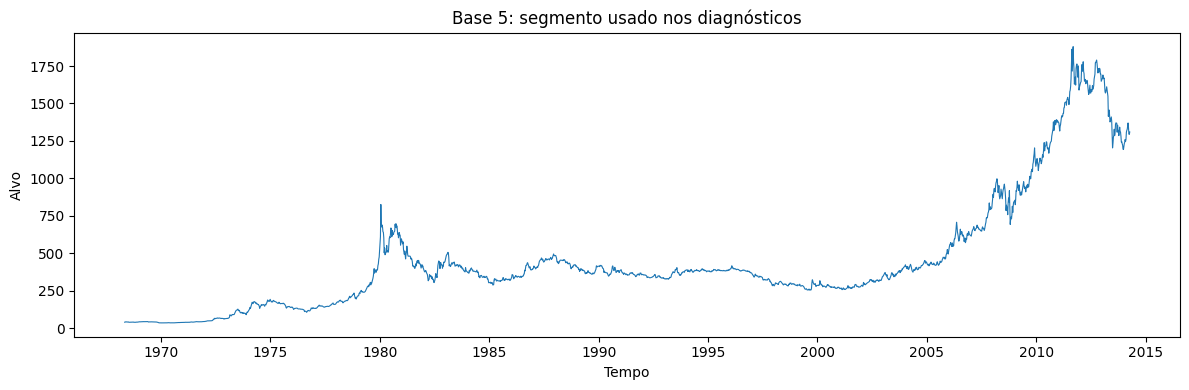

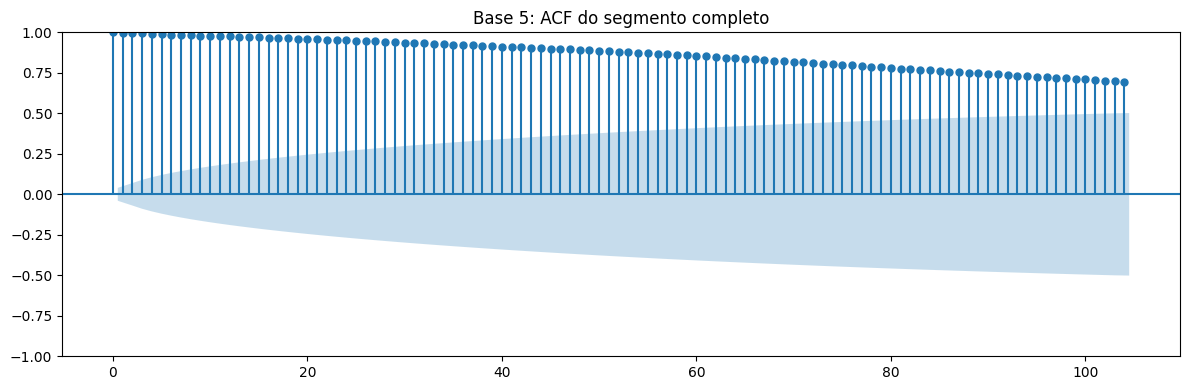

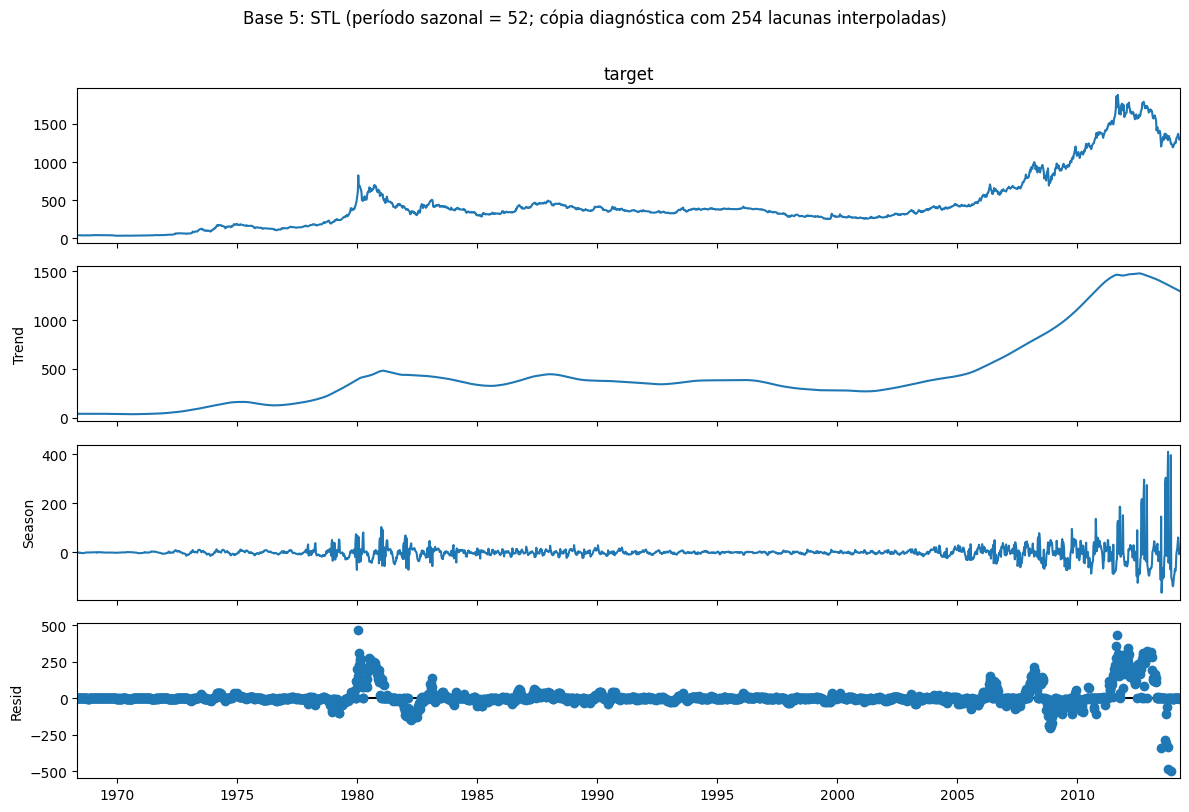

,segment_start,segment_end,segment_points,stl_seasonal_period,acf_lags,diagnostic_interpolated_values
0,1968-05-03,2014-04-11,2398,52,104,254


In [2]:
figure, axis = plt.subplots(figsize=(12, 4))
axis.plot(cleaned["timestamp"], cleaned["target"], linewidth=0.7)
axis.set(title=f"Base {BASE_ID}: alvo após tratamento", xlabel="Tempo", ylabel="Alvo")
figure.tight_layout()
plt.show()

diagnostic = plot_cleaned_diagnostics(
    cleaned,
    BASE_ID,
    ROOT / "reports" / "generated" / "exploration" / f"base{BASE_ID}",
)
display(pd.DataFrame([{
    "segment_start": diagnostic.data["timestamp"].min(),
    "segment_end": diagnostic.data["timestamp"].max(),
    "segment_points": len(diagnostic.data),
    "stl_seasonal_period": diagnostic.seasonal_period,
    "acf_lags": diagnostic.acf_lags,
    "diagnostic_interpolated_values": diagnostic.diagnostic_interpolated_values,
}]))
